# E5 — Multi-embedding latent landscape

## Objective

Determine whether the organization of the phage-lytic sequence universe is representation-dependent
or emerges consistently across independently learned protein-language-model embeddings.

## Frozen representation scope

E5 **does not generate embeddings**.

Only embedding matrices that already exist as completed project assets are analyzed:

- **ESM2-T6 8M** — 320 dimensions
- **ESM2-T30 150M** — 640 dimensions

Both were previously generated with the same representation contract:

- canonical 20-aa sequences only;
- maximum sequence length 1024;
- last hidden layer;
- mean layer aggregation;
- mean sequence pooling;
- FP32.

No model is downloaded, loaded, or executed in this notebook. No call to Sylphy, PyTorch, Transformers,
Hugging Face, or ESM is made. If a required embedding parquet is absent, E5 stops.

The current E5 question is therefore:

> Does the latent organization observed with ESM2-T6 also emerge with ESM2-T30, or does it depend
> strongly on model scale/representation?

T30 remains the representation used by the production classifier, but is **not** treated as the sole
valid EDA representation.

## Common embedding universe

The two embedding tables are audited through `sequence_uid`. E5 operates only on their exact common
sequence universe. The frozen E0 universe remains the source of biological/evidence labels.

Sequences absent from the precomputed PLM contract are **not embedded again** and are not imputed.

## Geometry

Each embedding is analyzed independently in its native latent space.

### Visualization

- Incremental PCA is fitted on the complete common embedding universe.
- UMAP is fitted only on a fixed balanced visualization sample.
- UMAP uses cosine distance and is used for visualization only.

### Quantitative geometry

All quantitative metrics are calculated in the original embedding space using **cosine geometry**,
not on PCA or UMAP coordinates.

For each representation and balanced scope we quantify:

- silhouette score;
- within-class cosine dispersion around the class centroid;
- between-class centroid cosine distances;
- centroid separation ratio;
- kNN same-label fraction;
- complete class-to-class nearest-neighbor composition;
- local enrichment relative to the balanced null expectation.

The same sequence IDs are reused for T6 and T30 so model comparisons are paired.

## Balanced scopes

- `global_three_state`: P_core / N_easy / N_hard
- `global_binary`: P_core / N_mixed
- `clean_subtypes`: Endolysin / Depolymerase / VAL

## Cross-embedding agreement

In addition to comparing class-geometry summaries, E5 directly compares T6 and T30 on fixed shared
audit samples using:

- Spearman correlation of pairwise cosine distances;
- mean Jaccard overlap of k-nearest-neighbor sets.

These metrics ask whether the two PLMs preserve similar sequence-level geometry, not merely whether
they achieve similar class separation.

## Principal outputs

For each representation:

- `embedding_<rep>_pca.tsv`
- `embedding_<rep>_umap.tsv`
- `embedding_<rep>_geometry.tsv`
- `embedding_<rep>_neighbors.tsv`

Cross-representation:

- `embedding_availability_audit.tsv`
- `cross_embedding_geometry_summary.tsv`
- `cross_embedding_agreement.tsv`

In [15]:
from pathlib import Path
import json
import re

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

import pyarrow as pa
import pyarrow.parquet as pq

from sklearn.decomposition import IncrementalPCA
from sklearn.metrics import silhouette_score
from sklearn.neighbors import NearestNeighbors

from scipy.spatial.distance import pdist
from scipy.stats import spearmanr

try:
    import umap
except ImportError as exc:
    raise ImportError(
        "E5 requires umap-learn for visualization. "
        "Install it in the active environment with: pip install umap-learn"
    ) from exc

from IPython.display import display

sns.set_theme(
    context="notebook",
    style="ticks",
    font_scale=1.0,
)

pd.set_option("display.max_columns", 180)
pd.set_option("display.width", 220)

RANDOM_SEED = 42

PCA_COMPONENTS = 20
PCA_BATCH_ROWS = 10_000

UMAP_N_NEIGHBORS = 30
UMAP_MIN_DIST = 0.20

NEIGHBOR_K_VALUES = [10, 25, 50]

GLOBAL_METRIC_REPEATS = 5
GLOBAL_THREE_STATE_N_PER_GROUP = 1_000
GLOBAL_BINARY_N_PER_GROUP = 1_500

SUBTYPE_METRIC_REPEATS = 10
SUBTYPE_N_PER_GROUP = 200

GLOBAL_VIZ_N_PER_GROUP = 3_000
SUBTYPE_VIZ_N_PER_GROUP = 200

CROSS_GLOBAL_N_PER_GROUP = 200
CROSS_SUBTYPE_N_PER_GROUP = 150
CROSS_K = 25

# Explicit guard: this notebook consumes frozen embeddings only.
EMBEDDING_GENERATION_DISABLED = True

## 1. Paths and frozen representation registry

In [16]:
cwd = Path.cwd().resolve()
PROJECT_ROOT = cwd.parent if cwd.name == "EDA" else cwd

E0_PATH = (
    PROJECT_ROOT
    / "EDA_results"
    / "E0"
    / "phagelytic_eda_universe.csv"
)

EMBED_ROOT = (
    PROJECT_ROOT
    / "data"
    / "representations"
    / "sylphy_embeddings"
    / "models"
)

REPRESENTATIONS = {
    "esm2_t6": {
        "display_name": "ESM2-T6 8M",
        "model": "facebook/esm2_t6_8m_ur50d",
        "slug": "facebook_esm2_t6_8m_ur50d",
        "expected_dimensions": 320,
    },
    "esm2_t30": {
        "display_name": "ESM2-T30 150M",
        "model": "facebook/esm2_t30_150m_ur50d",
        "slug": "facebook_esm2_t30_150m_ur50d",
        "expected_dimensions": 640,
    },
}

for rep, cfg in REPRESENTATIONS.items():
    cfg["directory"] = EMBED_ROOT / cfg["slug"]
    cfg["parquet"] = (
        cfg["directory"]
        / "embeddings_last_mean_fp32.parquet"
    )
    cfg["metadata"] = (
        cfg["directory"]
        / "metadata.json"
    )

RESULT_DIR = PROJECT_ROOT / "EDA_results" / "E5"
FIGURE_DIR = RESULT_DIR / "figures"

RESULT_DIR.mkdir(parents=True, exist_ok=True)
FIGURE_DIR.mkdir(parents=True, exist_ok=True)

AVAILABILITY_PATH = (
    RESULT_DIR
    / "embedding_availability_audit.tsv"
)
COMMON_UNIVERSE_PATH = (
    RESULT_DIR
    / "embedding_common_universe_summary.tsv"
)
SAMPLE_MANIFEST_PATH = (
    RESULT_DIR
    / "embedding_sample_manifest.tsv"
)
PCA_VARIANCE_PATH = (
    RESULT_DIR
    / "cross_embedding_pca_variance.tsv"
)
CROSS_GEOMETRY_PATH = (
    RESULT_DIR
    / "cross_embedding_geometry_summary.tsv"
)
CROSS_AGREEMENT_PATH = (
    RESULT_DIR
    / "cross_embedding_agreement.tsv"
)
METADATA_PATH = (
    RESULT_DIR
    / "e5_metadata.json"
)

if not E0_PATH.is_file():
    raise FileNotFoundError(
        f"Frozen E0 universe not found: {E0_PATH}"
    )

for rep, cfg in REPRESENTATIONS.items():
    if not cfg["parquet"].is_file():
        raise FileNotFoundError(
            f"Precomputed embedding parquet is absent for {rep}: "
            f"{cfg['parquet']}\n"
            "E5 will not generate embeddings."
        )

    if not cfg["metadata"].is_file():
        raise FileNotFoundError(
            f"Embedding metadata is absent for {rep}: "
            f"{cfg['metadata']}"
        )

print(f"Project root : {PROJECT_ROOT}")
print(f"Embedding root: {EMBED_ROOT}")
print(f"E5 results   : {RESULT_DIR}")

Project root : /home/david/Desktop/colabs/inta_project/phagelytic_core_project/phagelysclass
Embedding root: /home/david/Desktop/colabs/inta_project/phagelytic_core_project/phagelysclass/data/representations/sylphy_embeddings/models
E5 results   : /home/david/Desktop/colabs/inta_project/phagelytic_core_project/phagelysclass/EDA_results/E5


## 2. Audit embedding metadata and parquet schemas

In [17]:
NON_EMBEDDING_COLUMNS = {
    "sequence",
    "seq",
    "sequence_uid",
    "id",
    "length",
    "index",
}


def numeric_projection_columns(parquet_path):
    pf = pq.ParquetFile(parquet_path)
    schema = pf.schema_arrow

    feature_columns = []

    for field in schema:
        if field.name.lower() in NON_EMBEDDING_COLUMNS:
            continue

        if (
            pa.types.is_floating(field.type)
            or pa.types.is_integer(field.type)
        ):
            feature_columns.append(
                field.name
            )

    def projection_index(name):
        match = re.fullmatch(
            r"p_(\d+)",
            str(name),
        )
        return (
            int(match.group(1))
            if match
            else 10**9
        )

    feature_columns = sorted(
        feature_columns,
        key=projection_index,
    )

    return pf, feature_columns


availability_rows = []

for rep, cfg in REPRESENTATIONS.items():
    metadata = json.loads(
        cfg["metadata"].read_text(
            encoding="utf-8"
        )
    )

    pf, feature_columns = numeric_projection_columns(
        cfg["parquet"]
    )

    cfg["metadata_payload"] = metadata
    cfg["feature_columns"] = feature_columns
    cfg["row_count"] = int(
        pf.metadata.num_rows
    )

    if "sequence_uid" not in pf.schema_arrow.names:
        raise RuntimeError(
            f"{rep}: sequence_uid is absent from embedding parquet."
        )

    if cfg["row_count"] != int(
        metadata["row_count"]
    ):
        raise RuntimeError(
            f"{rep}: parquet/metadata row-count mismatch."
        )

    if len(feature_columns) != int(
        metadata["embedding_dimensions"]
    ):
        raise RuntimeError(
            f"{rep}: detected {len(feature_columns)} embedding dimensions "
            f"but metadata reports {metadata['embedding_dimensions']}."
        )

    if len(feature_columns) != cfg[
        "expected_dimensions"
    ]:
        raise RuntimeError(
            f"{rep}: expected {cfg['expected_dimensions']} dimensions "
            f"but found {len(feature_columns)}."
        )

    if metadata.get("status") != "completed":
        raise RuntimeError(
            f"{rep}: metadata status is not completed."
        )

    availability_rows.append(
        {
            "representation": rep,
            "display_name": cfg["display_name"],
            "model": cfg["model"],
            "parquet_exists": True,
            "metadata_status": metadata.get(
                "status"
            ),
            "row_count": cfg["row_count"],
            "embedding_dimensions": len(
                feature_columns
            ),
            "embedding_dtype": metadata.get(
                "embedding_dtype"
            ),
            "precision": metadata.get(
                "precision"
            ),
            "pool": metadata.get("pool"),
            "layers": metadata.get("layers"),
            "layer_agg": metadata.get(
                "layer_agg"
            ),
            "max_length": metadata.get(
                "max_length"
            ),
            "canonical_amino_acids_only": metadata.get(
                "canonical_amino_acids_only"
            ),
            "frozen_sequence_count": metadata.get(
                "frozen_sequence_count"
            ),
            "eligible_sequence_count": metadata.get(
                "eligible_sequence_count"
            ),
            "filtered_sequence_count": metadata.get(
                "filtered_sequence_count"
            ),
        }
    )

embedding_availability = pd.DataFrame(
    availability_rows
)

embedding_availability.to_csv(
    AVAILABILITY_PATH,
    sep="\t",
    index=False,
)

display(embedding_availability)

,representation,display_name,model,parquet_exists,metadata_status,row_count,embedding_dimensions,embedding_dtype,precision,pool,layers,layer_agg,max_length,canonical_amino_acids_only,frozen_sequence_count,eligible_sequence_count,filtered_sequence_count
0,esm2_t6,ESM2-T6 8M,facebook/esm2_t6_8m_ur50d,True,completed,434768,320,float32,fp32,mean,last,mean,1024,True,442329,434768,7561
1,esm2_t30,ESM2-T30 150M,facebook/esm2_t30_150m_ur50d,True,completed,434768,640,float32,fp32,mean,last,mean,1024,True,442329,434768,7561


## 3. Recover the exact common embedding universe

In [18]:
uid_tables = {}

for rep, cfg in REPRESENTATIONS.items():
    uids = pd.read_parquet(
        cfg["parquet"],
        columns=["sequence_uid"],
    )

    uids["sequence_uid"] = (
        uids["sequence_uid"]
        .astype(str)
    )

    if uids["sequence_uid"].duplicated().any():
        raise RuntimeError(
            f"{rep}: duplicated sequence_uid values."
        )

    uid_tables[rep] = uids


rep_names = list(
    REPRESENTATIONS
)

common_uids = set(
    uid_tables[
        rep_names[0]
    ]["sequence_uid"]
)

for rep in rep_names[1:]:
    common_uids &= set(
        uid_tables[
            rep
        ]["sequence_uid"]
    )

union_uids = set()

for rep in rep_names:
    union_uids |= set(
        uid_tables[
            rep
        ]["sequence_uid"]
    )

exact_uid_contract = all(
    set(
        uid_tables[
            rep
        ]["sequence_uid"]
    )
    == common_uids
    for rep in rep_names
)

if not exact_uid_contract:
    raise RuntimeError(
        "T6 and T30 do not have the same sequence_uid universe. "
        "E5 currently requires an exact paired universe."
    )


e0 = pd.read_csv(
    E0_PATH,
    usecols=[
        "sequence_uid",
        "sequence_state",
        "clean_subtype",
    ],
    dtype={
        "sequence_uid": str,
        "sequence_state": str,
        "clean_subtype": str,
    },
    low_memory=False,
)

assert len(e0) == 442_329
assert e0["sequence_uid"].is_unique

e0["binary_label"] = pd.Series(
    pd.NA,
    index=e0.index,
    dtype="string",
)

e0.loc[
    e0["sequence_state"].eq("P_core"),
    "binary_label",
] = "P_core"

e0.loc[
    e0["sequence_state"].isin(
        ["N_easy", "N_hard"]
    ),
    "binary_label",
] = "N_mixed"


CLEAN_SUBTYPES = [
    "endolysin",
    "depolymerase",
    "virion_associated_lytic_enzyme",
]

e0["subtype_label"] = pd.Series(
    pd.NA,
    index=e0.index,
    dtype="string",
)

clean_mask = e0[
    "clean_subtype"
].isin(
    CLEAN_SUBTYPES
)

e0.loc[
    clean_mask,
    "subtype_label",
] = (
    e0.loc[
        clean_mask,
        "clean_subtype",
    ]
    .astype("string")
)


common_labels = e0.loc[
    e0["sequence_uid"].isin(
        common_uids
    )
].copy()

if len(common_labels) != len(
    common_uids
):
    raise RuntimeError(
        "Common embedding universe could not be mapped one-to-one to E0."
    )

common_summary = pd.DataFrame(
    [
        {
            "scope": "E0_frozen",
            "n_sequences": len(e0),
        },
        {
            "scope": "embedding_common_universe",
            "n_sequences": len(
                common_labels
            ),
        },
        {
            "scope": "E0_without_precomputed_embeddings",
            "n_sequences": (
                len(e0)
                - len(common_labels)
            ),
        },
    ]
)

common_summary.to_csv(
    COMMON_UNIVERSE_PATH,
    sep="\t",
    index=False,
)

print(
    f"E0 frozen universe       : {len(e0):,}"
)
print(
    f"Common T6/T30 universe   : {len(common_labels):,}"
)
print(
    f"Not represented by PLMs  : "
    f"{len(e0) - len(common_labels):,}"
)

print()
print("Common-universe primary states")
display(
    common_labels[
        "sequence_state"
    ]
    .value_counts()
    .rename("n")
    .to_frame()
)

print()
print("Common-universe clean subtypes")
display(
    common_labels[
        "subtype_label"
    ]
    .value_counts(
        dropna=False
    )
    .rename("n")
    .to_frame()
)

E0 frozen universe       : 442,329
Common T6/T30 universe   : 434,768
Not represented by PLMs  : 7,561

Common-universe primary states


,n
sequence_state,
U_explicit,227256
U_other_unresolved,128181
N_easy,53867
P_core,11259
challenge_ambiguous_structural,9613
N_hard,4322
challenge_lytic_related,270



Common-universe clean subtypes


,n
subtype_label,
<NA>,424524
endolysin,9371
depolymerase,635
virion_associated_lytic_enzyme,238


## 4. Freeze paired balanced samples shared by T6 and T30

In [19]:
def balanced_sample_uids(
    data,
    group_col,
    groups,
    n_per_group,
    seed,
):
    rng = np.random.default_rng(
        seed
    )

    selected = []

    for group in groups:
        candidates = (
            data.loc[
                data[group_col].eq(
                    group
                ),
                "sequence_uid",
            ]
            .astype(str)
            .to_numpy()
        )

        if len(candidates) < n_per_group:
            raise RuntimeError(
                f"Not enough sequences for {group_col}={group}: "
                f"requested {n_per_group}, available {len(candidates)}."
            )

        sampled = rng.choice(
            candidates,
            size=n_per_group,
            replace=False,
        )

        selected.extend(
            sampled.tolist()
        )

    return selected


GLOBAL_THREE_GROUPS = [
    "P_core",
    "N_easy",
    "N_hard",
]

GLOBAL_BINARY_GROUPS = [
    "P_core",
    "N_mixed",
]

SUBTYPE_GROUPS = CLEAN_SUBTYPES


global_viz_uids = balanced_sample_uids(
    common_labels,
    group_col="sequence_state",
    groups=GLOBAL_THREE_GROUPS,
    n_per_group=GLOBAL_VIZ_N_PER_GROUP,
    seed=RANDOM_SEED,
)

subtype_viz_uids = balanced_sample_uids(
    common_labels.loc[
        common_labels[
            "subtype_label"
        ].notna()
    ],
    group_col="subtype_label",
    groups=SUBTYPE_GROUPS,
    n_per_group=SUBTYPE_VIZ_N_PER_GROUP,
    seed=RANDOM_SEED + 1,
)


SCOPE_CONFIG = {
    "global_three_state": {
        "group_col": "sequence_state",
        "groups": GLOBAL_THREE_GROUPS,
        "n_per_group": GLOBAL_THREE_STATE_N_PER_GROUP,
        "repeats": GLOBAL_METRIC_REPEATS,
    },
    "global_binary": {
        "group_col": "binary_label",
        "groups": GLOBAL_BINARY_GROUPS,
        "n_per_group": GLOBAL_BINARY_N_PER_GROUP,
        "repeats": GLOBAL_METRIC_REPEATS,
    },
    "clean_subtypes": {
        "group_col": "subtype_label",
        "groups": SUBTYPE_GROUPS,
        "n_per_group": SUBTYPE_N_PER_GROUP,
        "repeats": SUBTYPE_METRIC_REPEATS,
    },
}


METRIC_SAMPLE_PLANS = {}

for scope_name, config in SCOPE_CONFIG.items():
    scope_data = common_labels.loc[
        common_labels[
            config["group_col"]
        ].isin(
            config["groups"]
        )
    ]

    for repeat in range(
        config["repeats"]
    ):
        METRIC_SAMPLE_PLANS[
            (
                scope_name,
                repeat,
            )
        ] = balanced_sample_uids(
            scope_data,
            group_col=config[
                "group_col"
            ],
            groups=config[
                "groups"
            ],
            n_per_group=config[
                "n_per_group"
            ],
            seed=(
                RANDOM_SEED
                + repeat * 101
                + len(scope_name) * 10_000
            ),
        )


cross_global_uids = balanced_sample_uids(
    common_labels,
    group_col="sequence_state",
    groups=GLOBAL_THREE_GROUPS,
    n_per_group=CROSS_GLOBAL_N_PER_GROUP,
    seed=RANDOM_SEED + 900_001,
)

cross_subtype_uids = balanced_sample_uids(
    common_labels.loc[
        common_labels[
            "subtype_label"
        ].notna()
    ],
    group_col="subtype_label",
    groups=SUBTYPE_GROUPS,
    n_per_group=CROSS_SUBTYPE_N_PER_GROUP,
    seed=RANDOM_SEED + 900_002,
)


required_sample_uids = set(
    global_viz_uids
) | set(
    subtype_viz_uids
) | set(
    cross_global_uids
) | set(
    cross_subtype_uids
)

for sample_uids in METRIC_SAMPLE_PLANS.values():
    required_sample_uids |= set(
        sample_uids
    )


sample_manifest = common_labels.loc[
    common_labels[
        "sequence_uid"
    ].isin(
        required_sample_uids
    ),
    [
        "sequence_uid",
        "sequence_state",
        "binary_label",
        "clean_subtype",
        "subtype_label",
    ],
].copy()

sample_manifest[
    "in_global_viz_sample"
] = sample_manifest[
    "sequence_uid"
].isin(
    global_viz_uids
)

sample_manifest[
    "in_subtype_viz_sample"
] = sample_manifest[
    "sequence_uid"
].isin(
    subtype_viz_uids
)

sample_manifest[
    "in_cross_global_sample"
] = sample_manifest[
    "sequence_uid"
].isin(
    cross_global_uids
)

sample_manifest[
    "in_cross_subtype_sample"
] = sample_manifest[
    "sequence_uid"
].isin(
    cross_subtype_uids
)

sample_manifest.to_csv(
    SAMPLE_MANIFEST_PATH,
    sep="\t",
    index=False,
)

print(
    f"Global visualization sample : "
    f"{len(global_viz_uids):,}"
)
print(
    f"Subtype visualization sample: "
    f"{len(subtype_viz_uids):,}"
)
print(
    f"Union needed for E5 metrics : "
    f"{len(required_sample_uids):,}"
)

Global visualization sample : 9,000
Subtype visualization sample: 600
Union needed for E5 metrics : 26,894


## 5. Streaming helpers — consume embeddings without regenerating them

In [20]:
def batch_to_matrix(
    batch,
    feature_columns,
):
    frame = batch.to_pandas()

    matrix = frame[
        feature_columns
    ].to_numpy(
        dtype=np.float32,
        copy=True,
    )

    if not np.isfinite(
        matrix
    ).all():
        raise RuntimeError(
            "Non-finite values detected in frozen embedding matrix."
        )

    return frame, matrix


def fit_incremental_pca_on_parquet(
    parquet_path,
    feature_columns,
    n_components,
):
    model = IncrementalPCA(
        n_components=n_components,
        batch_size=PCA_BATCH_ROWS,
    )

    pf = pq.ParquetFile(
        parquet_path
    )

    for batch in pf.iter_batches(
        batch_size=PCA_BATCH_ROWS,
        columns=feature_columns,
    ):
        _, x = batch_to_matrix(
            batch,
            feature_columns,
        )

        model.partial_fit(x)

    return model


def extract_selected_embeddings(
    parquet_path,
    feature_columns,
    selected_uids,
):
    selected_uids = set(
        str(uid)
        for uid in selected_uids
    )

    pf = pq.ParquetFile(
        parquet_path
    )

    pieces = []

    for batch in pf.iter_batches(
        batch_size=PCA_BATCH_ROWS,
        columns=[
            "sequence_uid"
        ] + feature_columns,
    ):
        frame = batch.to_pandas()

        frame[
            "sequence_uid"
        ] = frame[
            "sequence_uid"
        ].astype(str)

        mask = frame[
            "sequence_uid"
        ].isin(
            selected_uids
        )

        if mask.any():
            pieces.append(
                frame.loc[
                    mask
                ].copy()
            )

    if not pieces:
        raise RuntimeError(
            "No selected embeddings were extracted."
        )

    selected = pd.concat(
        pieces,
        ignore_index=True,
    )

    if selected[
        "sequence_uid"
    ].duplicated().any():
        raise RuntimeError(
            "Selected embedding extraction produced duplicate sequence_uid."
        )

    observed = set(
        selected[
            "sequence_uid"
        ]
    )

    missing = (
        selected_uids
        - observed
    )

    if missing:
        raise RuntimeError(
            f"Selected embedding extraction missed {len(missing)} sequence_uid values."
        )

    matrix = selected[
        feature_columns
    ].to_numpy(
        dtype=np.float32,
        copy=True,
    )

    if not np.isfinite(
        matrix
    ).all():
        raise RuntimeError(
            "Selected embedding matrix contains NaN/Inf."
        )

    return selected


def l2_normalize_rows(x):
    norms = np.linalg.norm(
        x,
        axis=1,
        keepdims=True,
    )

    if np.any(norms == 0):
        raise RuntimeError(
            "Zero-norm embedding vector detected."
        )

    return x / norms


def cosine_distance_to_centroid(
    x_normalized,
    centroid_normalized,
):
    similarities = (
        x_normalized
        @ centroid_normalized
    )

    return (
        1.0
        - similarities
    )

## 6. Fit PCA on the complete common universe and extract the paired working samples

In [21]:
REP_DATA = {}
pca_variance_rows = []

for rep, cfg in REPRESENTATIONS.items():
    print()
    print("=" * 72)
    print(
        f"{cfg['display_name']} "
        f"({len(cfg['feature_columns'])}D)"
    )
    print("=" * 72)

    n_components = min(
        PCA_COMPONENTS,
        len(
            cfg[
                "feature_columns"
            ]
        ),
    )

    pca_model = fit_incremental_pca_on_parquet(
        cfg["parquet"],
        cfg["feature_columns"],
        n_components=n_components,
    )

    selected = extract_selected_embeddings(
        cfg["parquet"],
        cfg["feature_columns"],
        required_sample_uids,
    )

    selected = sample_manifest.merge(
        selected,
        on="sequence_uid",
        how="left",
        validate="one_to_one",
    )

    if selected[
        cfg[
            "feature_columns"
        ]
    ].isna().any().any():
        raise RuntimeError(
            f"{rep}: missing embeddings after sample join."
        )

    REP_DATA[rep] = {
        "pca_model": pca_model,
        "sample": selected,
    }

    cumulative = np.cumsum(
        pca_model.explained_variance_ratio_
    )

    for component_idx, ratio in enumerate(
        pca_model.explained_variance_ratio_,
        start=1,
    ):
        pca_variance_rows.append(
            {
                "representation": rep,
                "display_name": cfg["display_name"],
                "component": component_idx,
                "explained_variance_ratio": float(
                    ratio
                ),
                "cumulative_explained_variance_ratio": float(
                    cumulative[
                        component_idx - 1
                    ]
                ),
            }
        )


pca_variance = pd.DataFrame(
    pca_variance_rows
)

pca_variance.to_csv(
    PCA_VARIANCE_PATH,
    sep="\t",
    index=False,
)

display(
    pca_variance.loc[
        pca_variance[
            "component"
        ].isin(
            [1, 2, 5, 10, 20]
        )
    ]
)


ESM2-T6 8M (320D)

ESM2-T30 150M (640D)


,representation,display_name,component,explained_variance_ratio,cumulative_explained_variance_ratio
0,esm2_t6,ESM2-T6 8M,1,0.132739,0.132739
1,esm2_t6,ESM2-T6 8M,2,0.111998,0.244736
4,esm2_t6,ESM2-T6 8M,5,0.058510,0.472303
9,esm2_t6,ESM2-T6 8M,10,0.023769,0.633659
19,esm2_t6,ESM2-T6 8M,20,0.009140,0.769906
20,esm2_t30,ESM2-T30 150M,1,0.206255,0.206255
21,esm2_t30,ESM2-T30 150M,2,0.096993,0.303247
24,esm2_t30,ESM2-T30 150M,5,0.049135,0.481192
29,esm2_t30,ESM2-T30 150M,10,0.018754,0.610908
39,esm2_t30,ESM2-T30 150M,20,0.008681,0.739245


## 7. PCA and UMAP coordinates for paired visualization samples

In [22]:
def save_representation_coordinates(
    rep,
    cfg,
    rep_data,
):
    sample = rep_data[
        "sample"
    ]

    features = cfg[
        "feature_columns"
    ]

    x = sample[
        features
    ].to_numpy(
        dtype=np.float32,
        copy=True,
    )

    pca_coords = rep_data[
        "pca_model"
    ].transform(x)

    coordinate_base = sample[
        [
            "sequence_uid",
            "sequence_state",
            "binary_label",
            "clean_subtype",
            "subtype_label",
            "in_global_viz_sample",
            "in_subtype_viz_sample",
        ]
    ].copy()

    pca_table = coordinate_base.copy()

    for idx in range(
        min(
            5,
            pca_coords.shape[1],
        )
    ):
        pca_table[
            f"PC{idx + 1}"
        ] = pca_coords[
            :,
            idx
        ]

    pca_path = (
        RESULT_DIR
        / f"embedding_{rep}_pca.tsv"
    )

    pca_table.to_csv(
        pca_path,
        sep="\t",
        index=False,
    )

    viz_mask = (
        sample[
            "in_global_viz_sample"
        ]
        | sample[
            "in_subtype_viz_sample"
        ]
    )

    viz_sample = sample.loc[
        viz_mask
    ].copy()

    viz_x = viz_sample[
        features
    ].to_numpy(
        dtype=np.float32,
        copy=True,
    )

    umap_model = umap.UMAP(
        n_components=2,
        n_neighbors=UMAP_N_NEIGHBORS,
        min_dist=UMAP_MIN_DIST,
        metric="cosine",
        random_state=RANDOM_SEED,
        transform_seed=RANDOM_SEED,
        low_memory=True,
    )

    umap_coords = umap_model.fit_transform(
        viz_x
    )

    umap_table = viz_sample[
        [
            "sequence_uid",
            "sequence_state",
            "binary_label",
            "clean_subtype",
            "subtype_label",
            "in_global_viz_sample",
            "in_subtype_viz_sample",
        ]
    ].copy()

    umap_table[
        "UMAP1"
    ] = umap_coords[:, 0]

    umap_table[
        "UMAP2"
    ] = umap_coords[:, 1]

    umap_path = (
        RESULT_DIR
        / f"embedding_{rep}_umap.tsv"
    )

    umap_table.to_csv(
        umap_path,
        sep="\t",
        index=False,
    )

    rep_data[
        "pca_coordinates"
    ] = pca_table

    rep_data[
        "umap_coordinates"
    ] = umap_table

    rep_data[
        "pca_path"
    ] = pca_path

    rep_data[
        "umap_path"
    ] = umap_path

    print(f"Saved: {pca_path}")
    print(f"Saved: {umap_path}")


for rep, cfg in REPRESENTATIONS.items():
    save_representation_coordinates(
        rep,
        cfg,
        REP_DATA[rep],
    )

/home/david/miniconda3/envs/phagelysclass/lib/python3.12/site-packages/umap/umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(


Saved: /home/david/Desktop/colabs/inta_project/phagelytic_core_project/phagelysclass/EDA_results/E5/embedding_esm2_t6_pca.tsv
Saved: /home/david/Desktop/colabs/inta_project/phagelytic_core_project/phagelysclass/EDA_results/E5/embedding_esm2_t6_umap.tsv


/home/david/miniconda3/envs/phagelysclass/lib/python3.12/site-packages/umap/umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(


Saved: /home/david/Desktop/colabs/inta_project/phagelytic_core_project/phagelysclass/EDA_results/E5/embedding_esm2_t30_pca.tsv
Saved: /home/david/Desktop/colabs/inta_project/phagelytic_core_project/phagelysclass/EDA_results/E5/embedding_esm2_t30_umap.tsv


## 8. Quantitative latent geometry in the original embedding space

In [23]:
def sample_by_uid_order(
    frame,
    uid_order,
):
    indexed = frame.set_index(
        "sequence_uid",
        drop=False,
    )

    return (
        indexed.loc[
            [
                str(uid)
                for uid in uid_order
            ]
        ]
        .reset_index(
            drop=True
        )
    )


def latent_geometry_for_sample(
    sample_df,
    features,
    group_col,
    groups,
    k_values,
    silhouette_seed,
):
    labels = (
        sample_df[
            group_col
        ]
        .astype(str)
        .to_numpy()
    )

    x = sample_df[
        features
    ].to_numpy(
        dtype=np.float32,
        copy=True,
    )

    x_normalized = l2_normalize_rows(
        x
    )

    silhouette = float(
        silhouette_score(
            x,
            labels,
            metric="cosine",
            sample_size=min(
                1_500,
                len(x),
            ),
            random_state=silhouette_seed,
        )
    )

    centroids = {}
    within = {}

    for group in groups:
        group_matrix = x_normalized[
            labels == group
        ]

        centroid = group_matrix.mean(
            axis=0
        )

        centroid_norm = np.linalg.norm(
            centroid
        )

        if centroid_norm == 0:
            raise RuntimeError(
                f"Zero-norm centroid for {group}."
            )

        centroid = (
            centroid
            / centroid_norm
        )

        centroids[
            group
        ] = centroid

        within[
            group
        ] = float(
            np.mean(
                cosine_distance_to_centroid(
                    group_matrix,
                    centroid,
                )
            )
        )

    centroid_distances = []

    for i, group_a in enumerate(
        groups
    ):
        for group_b in groups[
            i + 1:
        ]:
            distance = float(
                1.0
                - np.dot(
                    centroids[
                        group_a
                    ],
                    centroids[
                        group_b
                    ],
                )
            )

            centroid_distances.append(
                (
                    group_a,
                    group_b,
                    distance,
                )
            )

    mean_within = float(
        np.mean(
            list(
                within.values()
            )
        )
    )

    mean_between = float(
        np.mean(
            [
                distance
                for (
                    _,
                    _,
                    distance,
                ) in centroid_distances
            ]
        )
    )

    separation_ratio = (
        mean_between
        / mean_within
        if mean_within > 0
        else np.nan
    )

    geometry_rows = [
        {
            "metric": "silhouette_cosine",
            "group_a": "",
            "group_b": "",
            "k": np.nan,
            "value": silhouette,
        },
        {
            "metric": "mean_within_centroid_cosine_distance",
            "group_a": "",
            "group_b": "",
            "k": np.nan,
            "value": mean_within,
        },
        {
            "metric": "mean_between_centroid_cosine_distance",
            "group_a": "",
            "group_b": "",
            "k": np.nan,
            "value": mean_between,
        },
        {
            "metric": "centroid_separation_ratio",
            "group_a": "",
            "group_b": "",
            "k": np.nan,
            "value": separation_ratio,
        },
    ]

    for group, value in within.items():
        geometry_rows.append(
            {
                "metric": "within_centroid_cosine_distance",
                "group_a": group,
                "group_b": "",
                "k": np.nan,
                "value": value,
            }
        )

    for (
        group_a,
        group_b,
        value,
    ) in centroid_distances:
        geometry_rows.append(
            {
                "metric": "centroid_cosine_distance",
                "group_a": group_a,
                "group_b": group_b,
                "k": np.nan,
                "value": value,
            }
        )


    neighborhood_rows = []

    for k in k_values:
        if k >= len(x):
            raise RuntimeError(
                f"k={k} invalid for n={len(x)}."
            )

        nn = NearestNeighbors(
            n_neighbors=k + 1,
            metric="cosine",
            algorithm="brute",
            n_jobs=-1,
        )

        nn.fit(x)

        neighbor_indices = nn.kneighbors(
            x,
            return_distance=False,
        )[:, 1:]

        neighbor_labels = labels[
            neighbor_indices
        ]

        baseline_fraction = (
            1.0
            / len(groups)
        )

        same_label_macro = []

        for focal_group in groups:
            focal_neighbors = (
                neighbor_labels[
                    labels == focal_group
                ]
            )

            same_fraction = float(
                np.mean(
                    focal_neighbors
                    == focal_group
                )
            )

            same_label_macro.append(
                same_fraction
            )

            for neighbor_group in groups:
                fraction = float(
                    np.mean(
                        focal_neighbors
                        == neighbor_group
                    )
                )

                enrichment = (
                    fraction
                    / baseline_fraction
                )

                neighborhood_rows.append(
                    {
                        "k": k,
                        "focal_group": focal_group,
                        "neighbor_group": neighbor_group,
                        "neighbor_fraction": fraction,
                        "balanced_expected_fraction": baseline_fraction,
                        "local_enrichment": enrichment,
                    }
                )

        geometry_rows.append(
            {
                "metric": "macro_knn_same_label_fraction",
                "group_a": "",
                "group_b": "",
                "k": k,
                "value": float(
                    np.mean(
                        same_label_macro
                    )
                ),
            }
        )

    return (
        geometry_rows,
        neighborhood_rows,
    )

In [24]:
geometry_repeats_by_rep = {}
neighbor_repeats_by_rep = {}

for rep, cfg in REPRESENTATIONS.items():
    print()
    print(f"Geometry: {cfg['display_name']}")

    sample_frame = REP_DATA[
        rep
    ]["sample"]

    geometry_rows = []
    neighbor_rows = []

    for scope_name, config in SCOPE_CONFIG.items():
        for repeat in range(
            config[
                "repeats"
            ]
        ):
            uid_order = METRIC_SAMPLE_PLANS[
                (
                    scope_name,
                    repeat,
                )
            ]

            scope_sample = sample_by_uid_order(
                sample_frame,
                uid_order,
            )

            g_rows, n_rows = (
                latent_geometry_for_sample(
                    scope_sample,
                    cfg["feature_columns"],
                    group_col=config[
                        "group_col"
                    ],
                    groups=config[
                        "groups"
                    ],
                    k_values=NEIGHBOR_K_VALUES,
                    silhouette_seed=(
                        RANDOM_SEED
                        + repeat
                    ),
                )
            )

            for row in g_rows:
                row.update(
                    {
                        "representation": rep,
                        "scope": scope_name,
                        "repeat": repeat,
                    }
                )

            for row in n_rows:
                row.update(
                    {
                        "representation": rep,
                        "scope": scope_name,
                        "repeat": repeat,
                    }
                )

            geometry_rows.extend(
                g_rows
            )

            neighbor_rows.extend(
                n_rows
            )

    geometry_repeats = pd.DataFrame(
        geometry_rows
    )

    neighbor_repeats = pd.DataFrame(
        neighbor_rows
    )

    geometry_repeats_by_rep[
        rep
    ] = geometry_repeats

    neighbor_repeats_by_rep[
        rep
    ] = neighbor_repeats

    geometry_summary = (
        geometry_repeats
        .groupby(
            [
                "representation",
                "scope",
                "metric",
                "group_a",
                "group_b",
                "k",
            ],
            dropna=False,
        )["value"]
        .agg(
            mean="mean",
            std="std",
            median="median",
            q25=lambda x: x.quantile(
                0.25
            ),
            q75=lambda x: x.quantile(
                0.75
            ),
            n_repeats="size",
        )
        .reset_index()
    )

    neighbor_summary = (
        neighbor_repeats
        .groupby(
            [
                "representation",
                "scope",
                "k",
                "focal_group",
                "neighbor_group",
                "balanced_expected_fraction",
            ],
            dropna=False,
        )
        .agg(
            mean_neighbor_fraction=(
                "neighbor_fraction",
                "mean",
            ),
            std_neighbor_fraction=(
                "neighbor_fraction",
                "std",
            ),
            median_neighbor_fraction=(
                "neighbor_fraction",
                "median",
            ),
            mean_local_enrichment=(
                "local_enrichment",
                "mean",
            ),
            std_local_enrichment=(
                "local_enrichment",
                "std",
            ),
            n_repeats=(
                "local_enrichment",
                "size",
            ),
        )
        .reset_index()
    )

    geometry_path = (
        RESULT_DIR
        / f"embedding_{rep}_geometry.tsv"
    )

    neighbor_path = (
        RESULT_DIR
        / f"embedding_{rep}_neighbors.tsv"
    )

    geometry_repeats_path = (
        RESULT_DIR
        / f"embedding_{rep}_geometry_repeats.tsv"
    )

    neighbor_repeats_path = (
        RESULT_DIR
        / f"embedding_{rep}_neighbor_repeats.tsv"
    )

    geometry_summary.to_csv(
        geometry_path,
        sep="\t",
        index=False,
    )

    neighbor_summary.to_csv(
        neighbor_path,
        sep="\t",
        index=False,
    )

    geometry_repeats.to_csv(
        geometry_repeats_path,
        sep="\t",
        index=False,
    )

    neighbor_repeats.to_csv(
        neighbor_repeats_path,
        sep="\t",
        index=False,
    )

    REP_DATA[
        rep
    ]["geometry_summary"] = (
        geometry_summary
    )

    REP_DATA[
        rep
    ]["neighbor_summary"] = (
        neighbor_summary
    )

    print(f"Saved: {geometry_path}")
    print(f"Saved: {neighbor_path}")


Geometry: ESM2-T6 8M
Saved: /home/david/Desktop/colabs/inta_project/phagelytic_core_project/phagelysclass/EDA_results/E5/embedding_esm2_t6_geometry.tsv
Saved: /home/david/Desktop/colabs/inta_project/phagelytic_core_project/phagelysclass/EDA_results/E5/embedding_esm2_t6_neighbors.tsv

Geometry: ESM2-T30 150M
Saved: /home/david/Desktop/colabs/inta_project/phagelytic_core_project/phagelysclass/EDA_results/E5/embedding_esm2_t30_geometry.tsv
Saved: /home/david/Desktop/colabs/inta_project/phagelytic_core_project/phagelysclass/EDA_results/E5/embedding_esm2_t30_neighbors.tsv


## 9. Cross-embedding geometry summary

In [25]:
cross_geometry = pd.concat(
    [
        REP_DATA[
            rep
        ]["geometry_summary"]
        for rep in REPRESENTATIONS
    ],
    ignore_index=True,
)

cross_geometry.insert(
    0,
    "comparison_type",
    "class_geometry",
)

cross_geometry[
    "display_name"
] = cross_geometry[
    "representation"
].map(
    {
        rep: cfg[
            "display_name"
        ]
        for rep, cfg in REPRESENTATIONS.items()
    }
)

cross_geometry.to_csv(
    CROSS_GEOMETRY_PATH,
    sep="\t",
    index=False,
)

display(
    cross_geometry.loc[
        cross_geometry[
            "metric"
        ].isin(
            [
                "silhouette_cosine",
                "centroid_separation_ratio",
                "macro_knn_same_label_fraction",
            ]
        )
    ]
    .sort_values(
        [
            "scope",
            "metric",
            "k",
            "mean",
        ],
        ascending=[
            True,
            True,
            True,
            False,
        ],
    )
)

,comparison_type,representation,scope,metric,group_a,group_b,k,mean,std,median,q25,q75,n_repeats,display_name
3,class_geometry,esm2_t6,clean_subtypes,centroid_separation_ratio,,,NaN,1.006397,0.054821,1.028512,0.950893,1.037164,10,ESM2-T6 8M
39,class_geometry,esm2_t30,clean_subtypes,centroid_separation_ratio,,,NaN,0.879954,0.041868,0.887841,0.843091,0.904321,10,ESM2-T30 150M
40,class_geometry,esm2_t30,clean_subtypes,macro_knn_same_label_fraction,,,10.0,0.919267,0.006548,0.919167,0.917542,0.924167,10,ESM2-T30 150M
4,class_geometry,esm2_t6,clean_subtypes,macro_knn_same_label_fraction,,,10.0,0.886850,0.005182,0.887667,0.881833,0.890542,10,ESM2-T6 8M
41,class_geometry,esm2_t30,clean_subtypes,macro_knn_same_label_fraction,,,25.0,0.887187,0.006707,0.889133,0.885100,0.890033,10,ESM2-T30 150M
5,class_geometry,esm2_t6,clean_subtypes,macro_knn_same_label_fraction,,,25.0,0.845267,0.004659,0.845467,0.841700,0.848833,10,ESM2-T6 8M
42,class_geometry,esm2_t30,clean_subtypes,macro_knn_same_label_fraction,,,50.0,0.867973,0.006723,0.869550,0.867217,0.871433,10,ESM2-T30 150M
6,class_geometry,esm2_t6,clean_subtypes,macro_knn_same_label_fraction,,,50.0,0.814187,0.003819,0.814933,0.811533,0.817442,10,ESM2-T6 8M
45,class_geometry,esm2_t30,clean_subtypes,silhouette_cosine,,,NaN,0.219986,0.006866,0.220088,0.215286,0.225550,10,ESM2-T30 150M
9,class_geometry,esm2_t6,clean_subtypes,silhouette_cosine,,,NaN,0.219210,0.010382,0.220529,0.210073,0.224122,10,ESM2-T6 8M


## 10. Direct T6–T30 geometry agreement

In [26]:
def knn_index_sets(
    x,
    k,
):
    nn = NearestNeighbors(
        n_neighbors=k + 1,
        metric="cosine",
        algorithm="brute",
        n_jobs=-1,
    )

    nn.fit(x)

    indices = nn.kneighbors(
        x,
        return_distance=False,
    )[:, 1:]

    return indices


def mean_knn_jaccard(
    indices_a,
    indices_b,
):
    if indices_a.shape != indices_b.shape:
        raise RuntimeError(
            "kNN matrices have different shapes."
        )

    scores = []

    for row_a, row_b in zip(
        indices_a,
        indices_b,
    ):
        set_a = set(
            row_a.tolist()
        )

        set_b = set(
            row_b.tolist()
        )

        union = set_a | set_b

        score = (
            len(
                set_a & set_b
            )
            / len(union)
            if union
            else 1.0
        )

        scores.append(
            score
        )

    return float(
        np.mean(
            scores
        )
    )


agreement_rows = []

for (
    scope_name,
    uid_order,
    group_col,
    groups,
) in [
    (
        "global_three_state",
        cross_global_uids,
        "sequence_state",
        GLOBAL_THREE_GROUPS,
    ),
    (
        "clean_subtypes",
        cross_subtype_uids,
        "subtype_label",
        SUBTYPE_GROUPS,
    ),
]:
    matrices = {}

    for rep, cfg in REPRESENTATIONS.items():
        sample = sample_by_uid_order(
            REP_DATA[
                rep
            ]["sample"],
            uid_order,
        )

        x = sample[
            cfg[
                "feature_columns"
            ]
        ].to_numpy(
            dtype=np.float32,
            copy=True,
        )

        matrices[
            rep
        ] = x

    t6_x = matrices[
        "esm2_t6"
    ]

    t30_x = matrices[
        "esm2_t30"
    ]

    t6_distances = pdist(
        t6_x,
        metric="cosine",
    )

    t30_distances = pdist(
        t30_x,
        metric="cosine",
    )

    distance_rho = float(
        spearmanr(
            t6_distances,
            t30_distances,
        ).statistic
    )

    t6_neighbors = knn_index_sets(
        t6_x,
        CROSS_K,
    )

    t30_neighbors = knn_index_sets(
        t30_x,
        CROSS_K,
    )

    neighbor_jaccard = (
        mean_knn_jaccard(
            t6_neighbors,
            t30_neighbors,
        )
    )

    agreement_rows.extend(
        [
            {
                "scope": scope_name,
                "representation_a": "esm2_t6",
                "representation_b": "esm2_t30",
                "metric": "pairwise_cosine_distance_spearman",
                "k": np.nan,
                "n_sequences": len(
                    uid_order
                ),
                "value": distance_rho,
            },
            {
                "scope": scope_name,
                "representation_a": "esm2_t6",
                "representation_b": "esm2_t30",
                "metric": "knn_jaccard_overlap",
                "k": CROSS_K,
                "n_sequences": len(
                    uid_order
                ),
                "value": neighbor_jaccard,
            },
        ]
    )


cross_agreement = pd.DataFrame(
    agreement_rows
)

cross_agreement.to_csv(
    CROSS_AGREEMENT_PATH,
    sep="\t",
    index=False,
)

display(cross_agreement)

,scope,representation_a,representation_b,metric,k,n_sequences,value
0,global_three_state,esm2_t6,esm2_t30,pairwise_cosine_distance_spearman,NaN,600,0.556392
1,global_three_state,esm2_t6,esm2_t30,knn_jaccard_overlap,25.0,600,0.354165
2,clean_subtypes,esm2_t6,esm2_t30,pairwise_cosine_distance_spearman,NaN,450,0.697885
3,clean_subtypes,esm2_t6,esm2_t30,knn_jaccard_overlap,25.0,450,0.411154


## 11. Figures

In [27]:
def save_figure(
    fig,
    stem,
):
    png = (
        FIGURE_DIR
        / f"{stem}.png"
    )

    pdf = (
        FIGURE_DIR
        / f"{stem}.pdf"
    )

    fig.savefig(
        png,
        dpi=300,
        bbox_inches="tight",
    )

    fig.savefig(
        pdf,
        bbox_inches="tight",
    )

    print(f"Saved: {png}")
    print(f"Saved: {pdf}")


GLOBAL_HUE_ORDER = [
    "P_core",
    "N_easy",
    "N_hard",
]

SUBTYPE_HUE_ORDER = [
    "endolysin",
    "depolymerase",
    "virion_associated_lytic_enzyme",
]

Saved: /home/david/Desktop/colabs/inta_project/phagelytic_core_project/phagelysclass/EDA_results/E5/figures/E5_esm2_t6_PCA_global.png
Saved: /home/david/Desktop/colabs/inta_project/phagelytic_core_project/phagelysclass/EDA_results/E5/figures/E5_esm2_t6_PCA_global.pdf


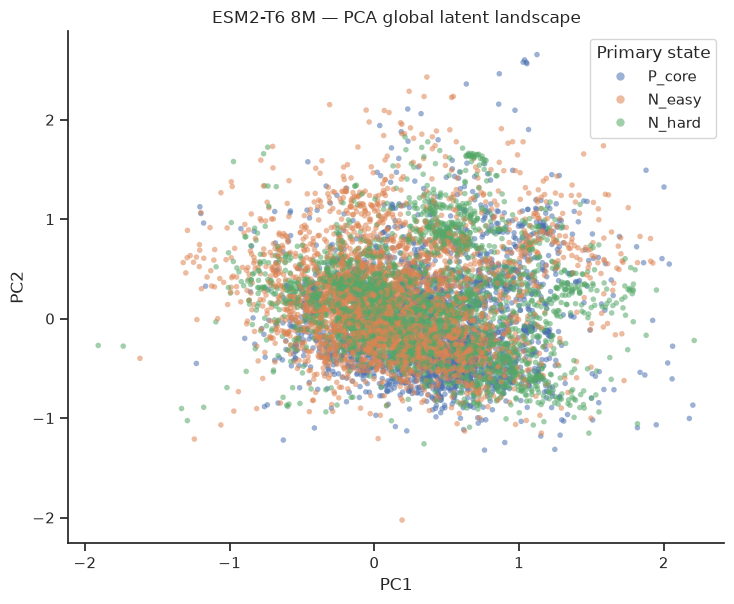

Saved: /home/david/Desktop/colabs/inta_project/phagelytic_core_project/phagelysclass/EDA_results/E5/figures/E5_esm2_t6_UMAP_global.png
Saved: /home/david/Desktop/colabs/inta_project/phagelytic_core_project/phagelysclass/EDA_results/E5/figures/E5_esm2_t6_UMAP_global.pdf


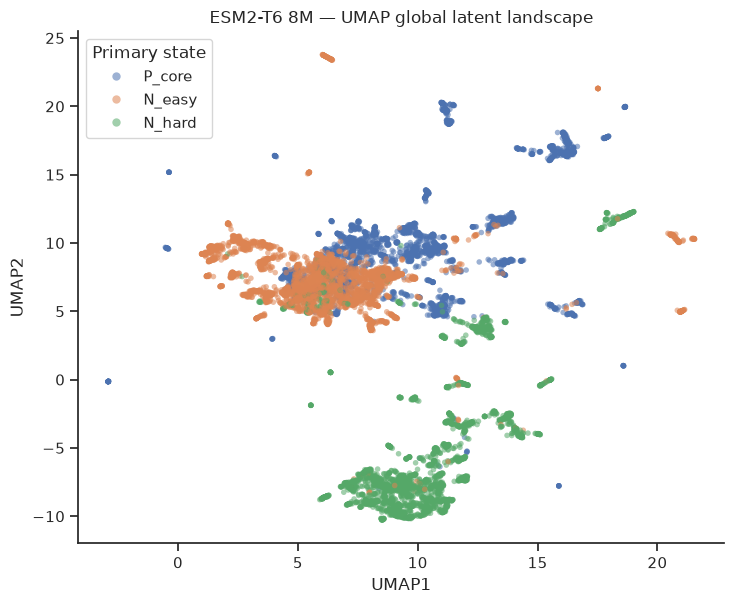

Saved: /home/david/Desktop/colabs/inta_project/phagelytic_core_project/phagelysclass/EDA_results/E5/figures/E5_esm2_t6_PCA_subtypes.png
Saved: /home/david/Desktop/colabs/inta_project/phagelytic_core_project/phagelysclass/EDA_results/E5/figures/E5_esm2_t6_PCA_subtypes.pdf


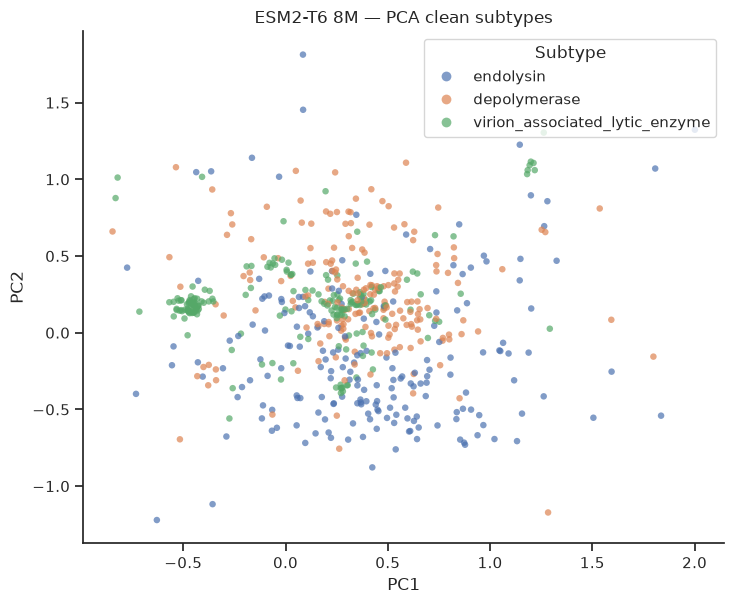

Saved: /home/david/Desktop/colabs/inta_project/phagelytic_core_project/phagelysclass/EDA_results/E5/figures/E5_esm2_t6_UMAP_subtypes.png
Saved: /home/david/Desktop/colabs/inta_project/phagelytic_core_project/phagelysclass/EDA_results/E5/figures/E5_esm2_t6_UMAP_subtypes.pdf


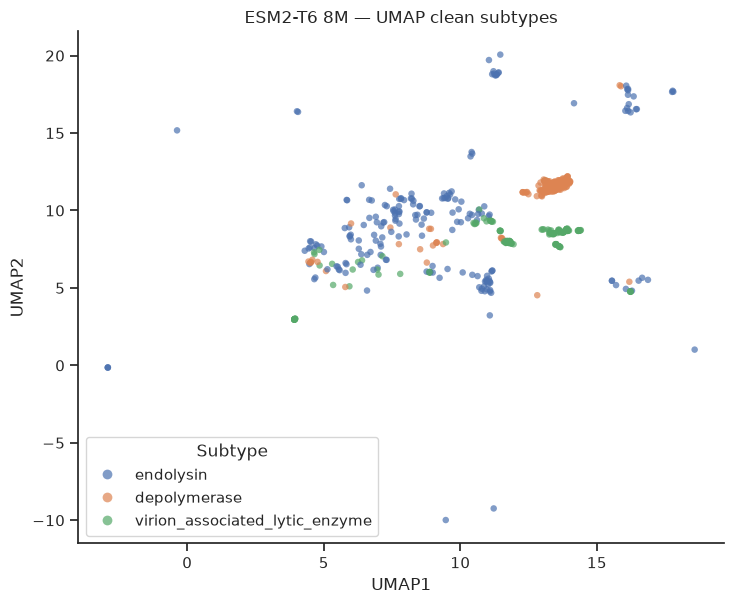

Saved: /home/david/Desktop/colabs/inta_project/phagelytic_core_project/phagelysclass/EDA_results/E5/figures/E5_esm2_t30_PCA_global.png
Saved: /home/david/Desktop/colabs/inta_project/phagelytic_core_project/phagelysclass/EDA_results/E5/figures/E5_esm2_t30_PCA_global.pdf


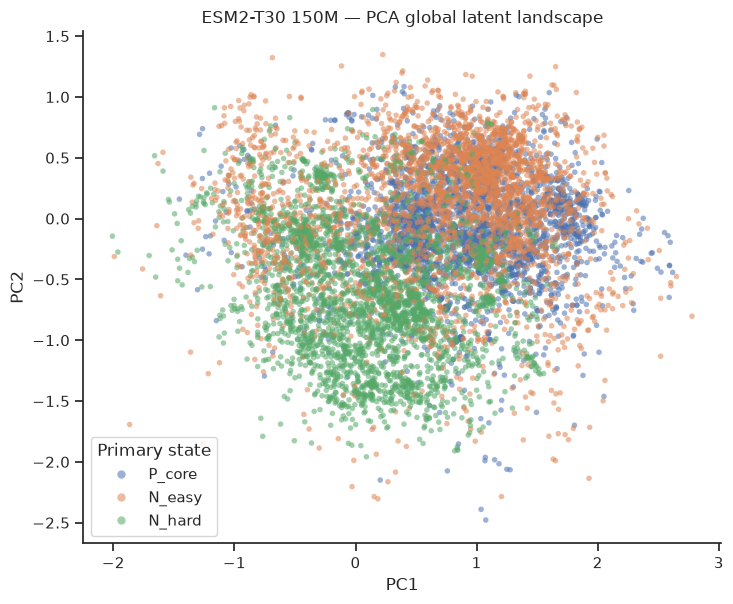

Saved: /home/david/Desktop/colabs/inta_project/phagelytic_core_project/phagelysclass/EDA_results/E5/figures/E5_esm2_t30_UMAP_global.png
Saved: /home/david/Desktop/colabs/inta_project/phagelytic_core_project/phagelysclass/EDA_results/E5/figures/E5_esm2_t30_UMAP_global.pdf


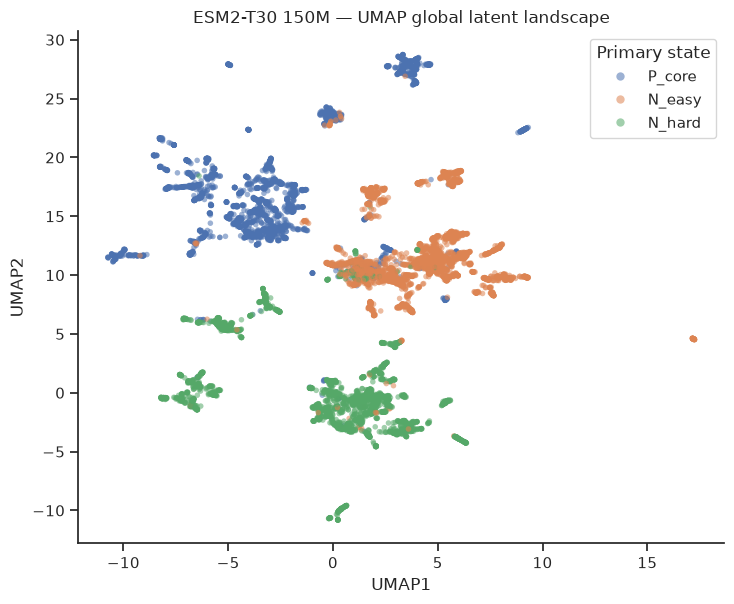

Saved: /home/david/Desktop/colabs/inta_project/phagelytic_core_project/phagelysclass/EDA_results/E5/figures/E5_esm2_t30_PCA_subtypes.png
Saved: /home/david/Desktop/colabs/inta_project/phagelytic_core_project/phagelysclass/EDA_results/E5/figures/E5_esm2_t30_PCA_subtypes.pdf


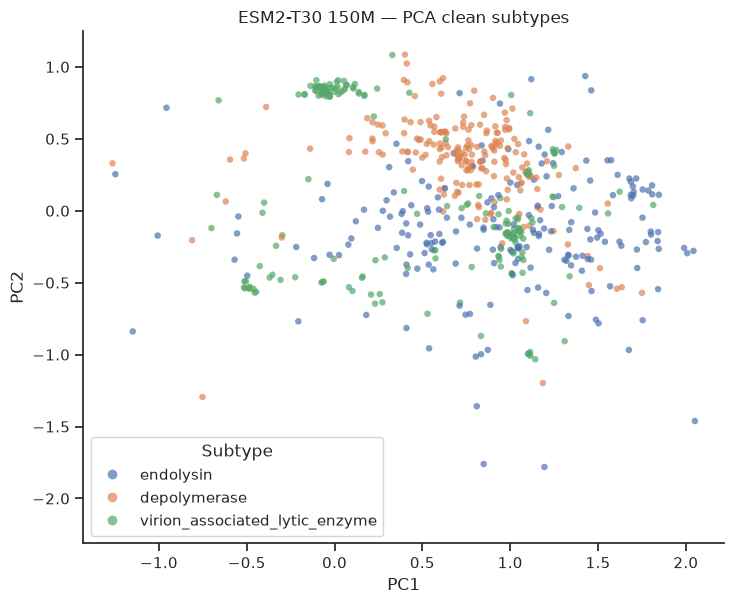

Saved: /home/david/Desktop/colabs/inta_project/phagelytic_core_project/phagelysclass/EDA_results/E5/figures/E5_esm2_t30_UMAP_subtypes.png
Saved: /home/david/Desktop/colabs/inta_project/phagelytic_core_project/phagelysclass/EDA_results/E5/figures/E5_esm2_t30_UMAP_subtypes.pdf


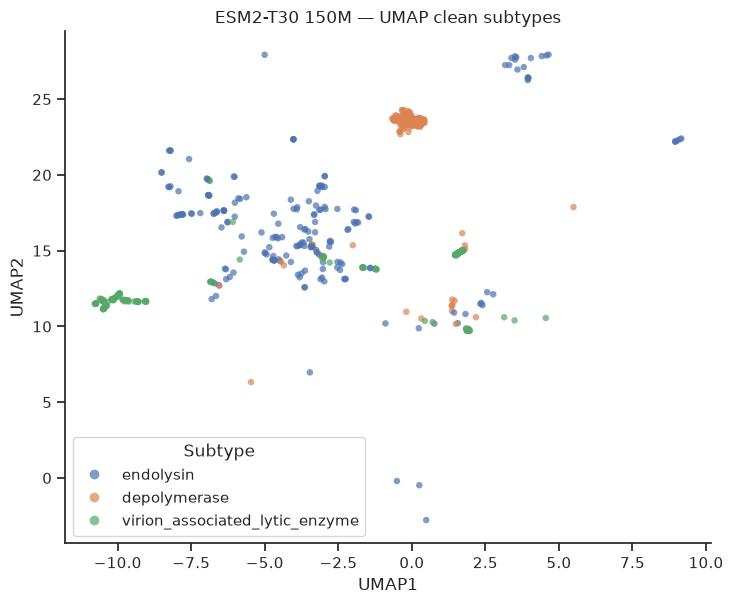

In [28]:
for rep, cfg in REPRESENTATIONS.items():
    pca_table = REP_DATA[
        rep
    ]["pca_coordinates"]

    umap_table = REP_DATA[
        rep
    ]["umap_coordinates"]

    # Global PCA
    plot_df = pca_table.loc[
        pca_table[
            "in_global_viz_sample"
        ]
        & pca_table[
            "sequence_state"
        ].isin(
            GLOBAL_HUE_ORDER
        )
    ]

    fig, ax = plt.subplots(
        figsize=(7.5, 6.2)
    )

    sns.scatterplot(
        data=plot_df,
        x="PC1",
        y="PC2",
        hue="sequence_state",
        hue_order=GLOBAL_HUE_ORDER,
        s=16,
        alpha=0.55,
        linewidth=0,
        ax=ax,
    )

    ax.set_title(
        f"{cfg['display_name']} — PCA global latent landscape"
    )
    ax.legend(
        title="Primary state",
        markerscale=1.5,
    )

    sns.despine()
    fig.tight_layout()

    save_figure(
        fig,
        f"E5_{rep}_PCA_global",
    )

    plt.show()

    # Global UMAP
    plot_df = umap_table.loc[
        umap_table[
            "in_global_viz_sample"
        ]
        & umap_table[
            "sequence_state"
        ].isin(
            GLOBAL_HUE_ORDER
        )
    ]

    fig, ax = plt.subplots(
        figsize=(7.5, 6.2)
    )

    sns.scatterplot(
        data=plot_df,
        x="UMAP1",
        y="UMAP2",
        hue="sequence_state",
        hue_order=GLOBAL_HUE_ORDER,
        s=16,
        alpha=0.55,
        linewidth=0,
        ax=ax,
    )

    ax.set_title(
        f"{cfg['display_name']} — UMAP global latent landscape"
    )
    ax.legend(
        title="Primary state",
        markerscale=1.5,
    )

    sns.despine()
    fig.tight_layout()

    save_figure(
        fig,
        f"E5_{rep}_UMAP_global",
    )

    plt.show()

    # Subtype PCA
    plot_df = pca_table.loc[
        pca_table[
            "in_subtype_viz_sample"
        ]
        & pca_table[
            "subtype_label"
        ].isin(
            SUBTYPE_HUE_ORDER
        )
    ]

    fig, ax = plt.subplots(
        figsize=(7.5, 6.2)
    )

    sns.scatterplot(
        data=plot_df,
        x="PC1",
        y="PC2",
        hue="subtype_label",
        hue_order=SUBTYPE_HUE_ORDER,
        s=22,
        alpha=0.70,
        linewidth=0,
        ax=ax,
    )

    ax.set_title(
        f"{cfg['display_name']} — PCA clean subtypes"
    )
    ax.legend(
        title="Subtype",
        markerscale=1.5,
    )

    sns.despine()
    fig.tight_layout()

    save_figure(
        fig,
        f"E5_{rep}_PCA_subtypes",
    )

    plt.show()

    # Subtype UMAP
    plot_df = umap_table.loc[
        umap_table[
            "in_subtype_viz_sample"
        ]
        & umap_table[
            "subtype_label"
        ].isin(
            SUBTYPE_HUE_ORDER
        )
    ]

    fig, ax = plt.subplots(
        figsize=(7.5, 6.2)
    )

    sns.scatterplot(
        data=plot_df,
        x="UMAP1",
        y="UMAP2",
        hue="subtype_label",
        hue_order=SUBTYPE_HUE_ORDER,
        s=22,
        alpha=0.70,
        linewidth=0,
        ax=ax,
    )

    ax.set_title(
        f"{cfg['display_name']} — UMAP clean subtypes"
    )
    ax.legend(
        title="Subtype",
        markerscale=1.5,
    )

    sns.despine()
    fig.tight_layout()

    save_figure(
        fig,
        f"E5_{rep}_UMAP_subtypes",
    )

    plt.show()

Saved: /home/david/Desktop/colabs/inta_project/phagelytic_core_project/phagelysclass/EDA_results/E5/figures/E5_cross_silhouette_global_three_state.png
Saved: /home/david/Desktop/colabs/inta_project/phagelytic_core_project/phagelysclass/EDA_results/E5/figures/E5_cross_silhouette_global_three_state.pdf


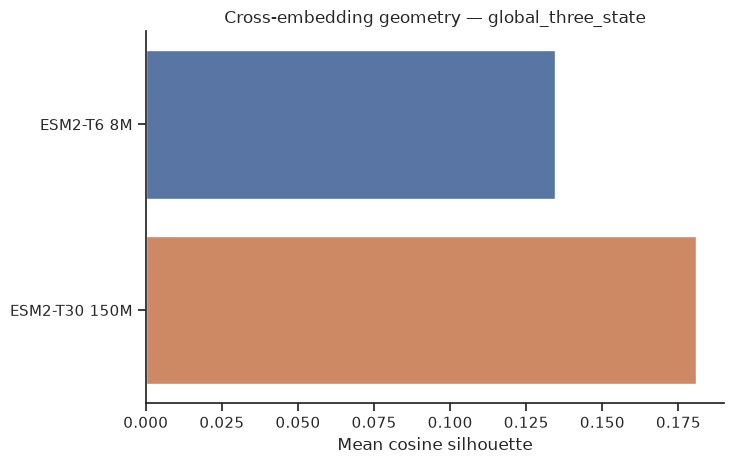

Saved: /home/david/Desktop/colabs/inta_project/phagelytic_core_project/phagelysclass/EDA_results/E5/figures/E5_cross_silhouette_global_binary.png
Saved: /home/david/Desktop/colabs/inta_project/phagelytic_core_project/phagelysclass/EDA_results/E5/figures/E5_cross_silhouette_global_binary.pdf


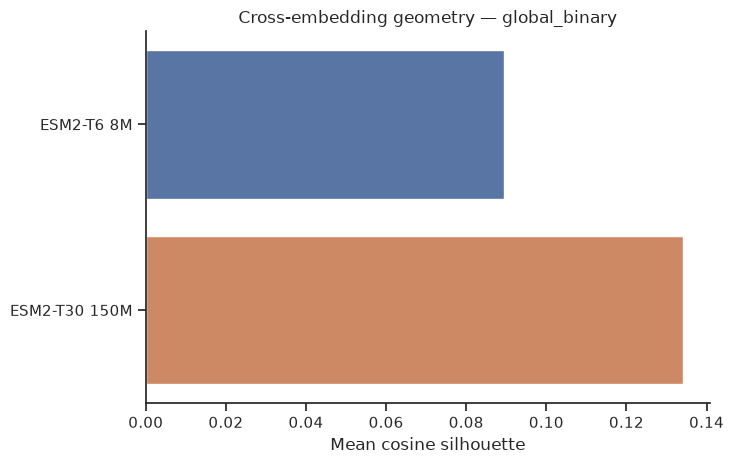

Saved: /home/david/Desktop/colabs/inta_project/phagelytic_core_project/phagelysclass/EDA_results/E5/figures/E5_cross_silhouette_clean_subtypes.png
Saved: /home/david/Desktop/colabs/inta_project/phagelytic_core_project/phagelysclass/EDA_results/E5/figures/E5_cross_silhouette_clean_subtypes.pdf


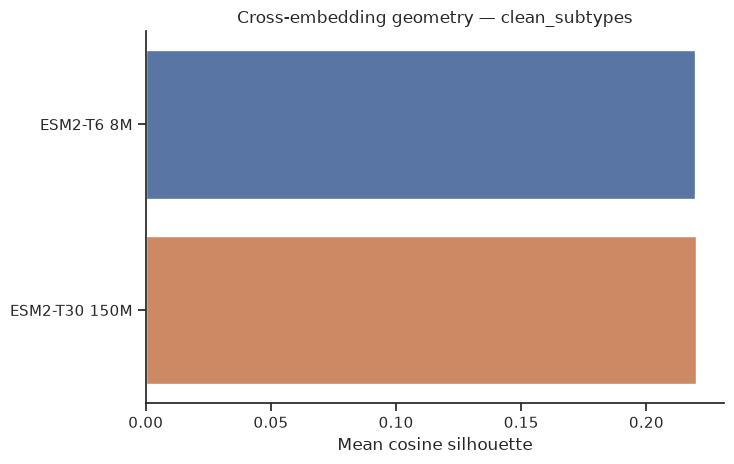

Saved: /home/david/Desktop/colabs/inta_project/phagelytic_core_project/phagelysclass/EDA_results/E5/figures/E5_cross_centroid_separation_global_three_state.png
Saved: /home/david/Desktop/colabs/inta_project/phagelytic_core_project/phagelysclass/EDA_results/E5/figures/E5_cross_centroid_separation_global_three_state.pdf


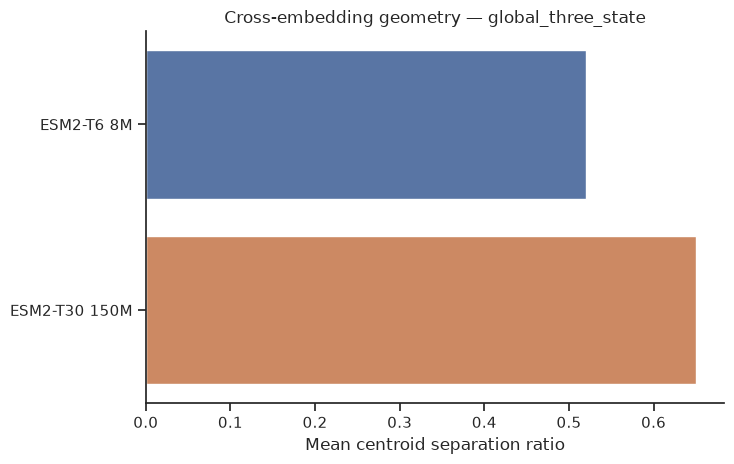

Saved: /home/david/Desktop/colabs/inta_project/phagelytic_core_project/phagelysclass/EDA_results/E5/figures/E5_cross_centroid_separation_global_binary.png
Saved: /home/david/Desktop/colabs/inta_project/phagelytic_core_project/phagelysclass/EDA_results/E5/figures/E5_cross_centroid_separation_global_binary.pdf


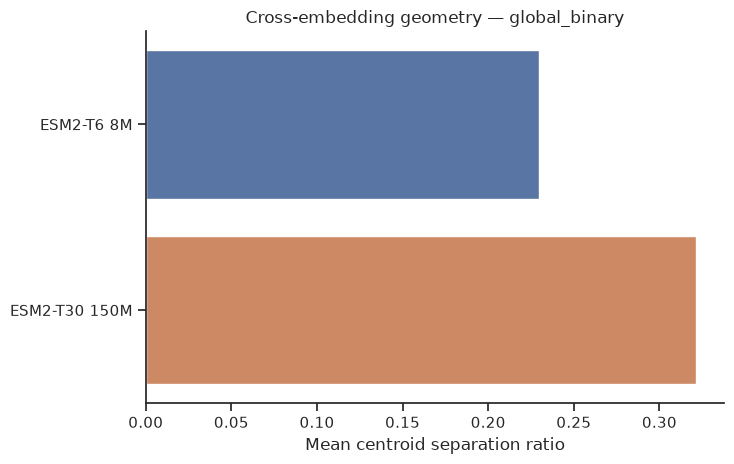

Saved: /home/david/Desktop/colabs/inta_project/phagelytic_core_project/phagelysclass/EDA_results/E5/figures/E5_cross_centroid_separation_clean_subtypes.png
Saved: /home/david/Desktop/colabs/inta_project/phagelytic_core_project/phagelysclass/EDA_results/E5/figures/E5_cross_centroid_separation_clean_subtypes.pdf


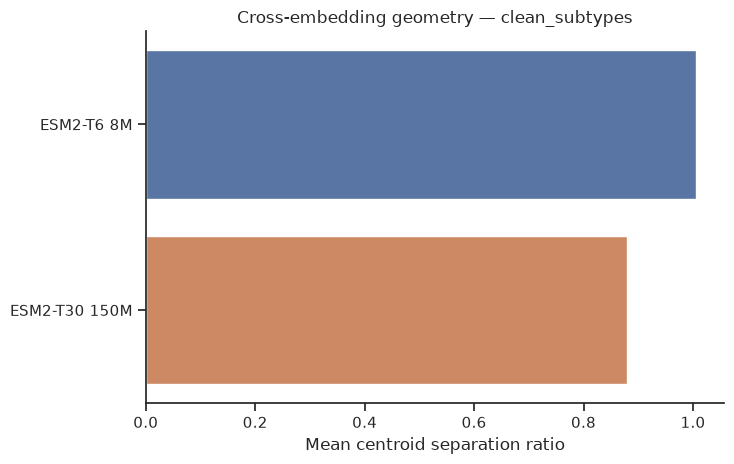

Saved: /home/david/Desktop/colabs/inta_project/phagelytic_core_project/phagelysclass/EDA_results/E5/figures/E5_cross_knn25_global_three_state.png
Saved: /home/david/Desktop/colabs/inta_project/phagelytic_core_project/phagelysclass/EDA_results/E5/figures/E5_cross_knn25_global_three_state.pdf


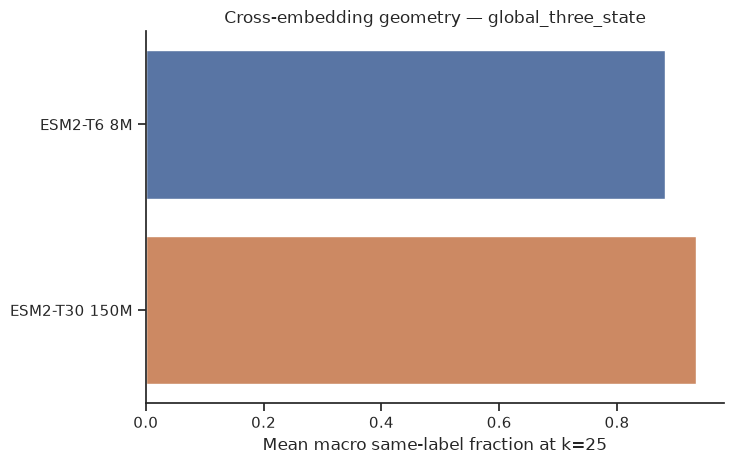

Saved: /home/david/Desktop/colabs/inta_project/phagelytic_core_project/phagelysclass/EDA_results/E5/figures/E5_cross_knn25_global_binary.png
Saved: /home/david/Desktop/colabs/inta_project/phagelytic_core_project/phagelysclass/EDA_results/E5/figures/E5_cross_knn25_global_binary.pdf


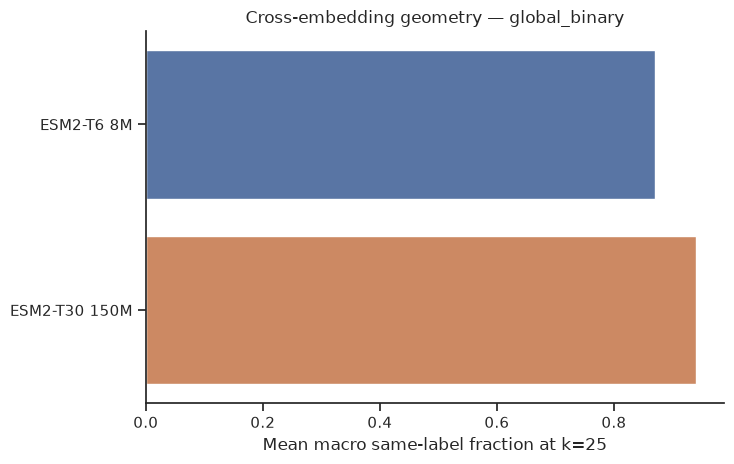

Saved: /home/david/Desktop/colabs/inta_project/phagelytic_core_project/phagelysclass/EDA_results/E5/figures/E5_cross_knn25_clean_subtypes.png
Saved: /home/david/Desktop/colabs/inta_project/phagelytic_core_project/phagelysclass/EDA_results/E5/figures/E5_cross_knn25_clean_subtypes.pdf


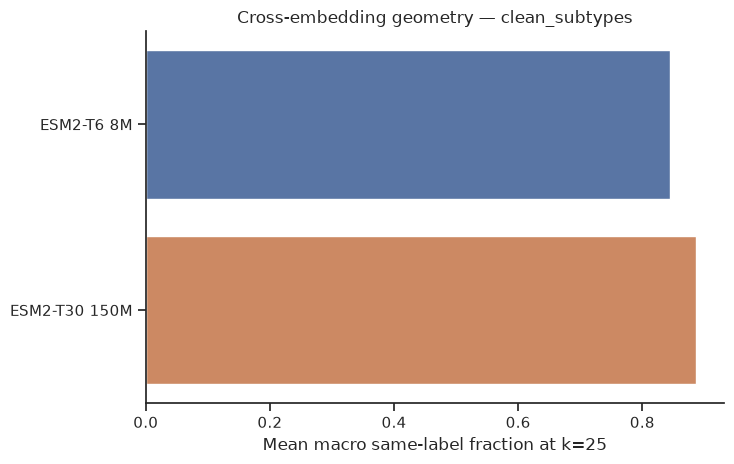

In [29]:
for metric, k, x_label, stem in [
    (
        "silhouette_cosine",
        np.nan,
        "Mean cosine silhouette",
        "silhouette",
    ),
    (
        "centroid_separation_ratio",
        np.nan,
        "Mean centroid separation ratio",
        "centroid_separation",
    ),
    (
        "macro_knn_same_label_fraction",
        25,
        "Mean macro same-label fraction at k=25",
        "knn25",
    ),
]:
    for scope_name in SCOPE_CONFIG:
        plot_df = cross_geometry.loc[
            cross_geometry[
                "scope"
            ].eq(
                scope_name
            )
            & cross_geometry[
                "metric"
            ].eq(
                metric
            )
        ].copy()

        if np.isfinite(k):
            plot_df = plot_df.loc[
                plot_df["k"].eq(k)
            ]

        fig, ax = plt.subplots(
            figsize=(7.5, 4.8)
        )

        sns.barplot(
            data=plot_df,
            y="display_name",
            x="mean",
            hue="display_name",
            dodge=False,
            legend=False,
            ax=ax,
        )

        ax.set_xlabel(
            x_label
        )
        ax.set_ylabel("")
        ax.set_title(
            f"Cross-embedding geometry — {scope_name}"
        )

        sns.despine()
        fig.tight_layout()

        save_figure(
            fig,
            f"E5_cross_{stem}_{scope_name}",
        )

        plt.show()

## 12. Final closure audit

In [30]:
assert EMBEDDING_GENERATION_DISABLED is True
assert set(REPRESENTATIONS) == {
    "esm2_t6",
    "esm2_t30",
}

assert len(e0) == 442_329
assert len(common_labels) == 434_768
assert exact_uid_contract

assert (
    REPRESENTATIONS[
        "esm2_t6"
    ]["expected_dimensions"]
    == 320
)

assert (
    REPRESENTATIONS[
        "esm2_t30"
    ]["expected_dimensions"]
    == 640
)

assert not embedding_availability.empty
assert not pca_variance.empty
assert not cross_geometry.empty
assert not cross_agreement.empty

for rep in REPRESENTATIONS:
    cfg = REPRESENTATIONS[
        rep
    ]

    assert (
        len(
            cfg[
                "feature_columns"
            ]
        )
        == cfg[
            "expected_dimensions"
        ]
    )

    assert not REP_DATA[
        rep
    ]["geometry_summary"].empty

    assert not REP_DATA[
        rep
    ]["neighbor_summary"].empty

    required_rep_outputs = [
        RESULT_DIR
        / f"embedding_{rep}_pca.tsv",
        RESULT_DIR
        / f"embedding_{rep}_umap.tsv",
        RESULT_DIR
        / f"embedding_{rep}_geometry.tsv",
        RESULT_DIR
        / f"embedding_{rep}_neighbors.tsv",
        RESULT_DIR
        / f"embedding_{rep}_geometry_repeats.tsv",
        RESULT_DIR
        / f"embedding_{rep}_neighbor_repeats.tsv",
    ]

    for path in required_rep_outputs:
        assert path.is_file(), (
            f"Missing E5 output: {path}"
        )

assert set(
    cross_geometry[
        "representation"
    ]
) == set(
    REPRESENTATIONS
)

assert set(
    cross_agreement[
        "representation_a"
    ]
) == {
    "esm2_t6"
}

assert set(
    cross_agreement[
        "representation_b"
    ]
) == {
    "esm2_t30"
}

required_outputs = [
    AVAILABILITY_PATH,
    COMMON_UNIVERSE_PATH,
    SAMPLE_MANIFEST_PATH,
    PCA_VARIANCE_PATH,
    CROSS_GEOMETRY_PATH,
    CROSS_AGREEMENT_PATH,
]

for path in required_outputs:
    assert path.is_file(), (
        f"Missing E5 output: {path}"
    )


metadata = {
    "embedding_generation_disabled": True,
    "representations": {
        rep: {
            "display_name": cfg["display_name"],
            "model": cfg["model"],
            "dimensions": cfg["expected_dimensions"],
            "row_count": cfg["row_count"],
            "pool": cfg[
                "metadata_payload"
            ].get("pool"),
            "layers": cfg[
                "metadata_payload"
            ].get("layers"),
            "precision": cfg[
                "metadata_payload"
            ].get("precision"),
            "max_length": cfg[
                "metadata_payload"
            ].get("max_length"),
        }
        for rep, cfg in REPRESENTATIONS.items()
    },
    "frozen_e0_rows": int(
        len(e0)
    ),
    "common_embedding_rows": int(
        len(common_labels)
    ),
    "not_embedded_rows": int(
        len(e0)
        - len(common_labels)
    ),
    "distance_metric": "cosine",
    "pca_components": PCA_COMPONENTS,
    "umap_metric": "cosine",
    "umap_n_neighbors": UMAP_N_NEIGHBORS,
    "umap_min_dist": UMAP_MIN_DIST,
    "neighbor_k_values": NEIGHBOR_K_VALUES,
    "global_metric_repeats": GLOBAL_METRIC_REPEATS,
    "subtype_metric_repeats": SUBTYPE_METRIC_REPEATS,
    "cross_embedding_agreement_k": CROSS_K,
    "random_seed": RANDOM_SEED,
}

METADATA_PATH.write_text(
    json.dumps(
        metadata,
        indent=2,
    ),
    encoding="utf-8",
)

print("=" * 72)
print(
    "PASS — E5 multi-embedding latent landscape completed."
)
print("=" * 72)
print()
print(
    "No embeddings were generated in E5."
)
print(
    f"Representations analyzed: "
    f"{', '.join(REPRESENTATIONS)}"
)
print(
    f"Common embedding universe: "
    f"{len(common_labels):,}"
)
print(
    f"Results: {RESULT_DIR}"
)

PASS — E5 multi-embedding latent landscape completed.

No embeddings were generated in E5.
Representations analyzed: esm2_t6, esm2_t30
Common embedding universe: 434,768
Results: /home/david/Desktop/colabs/inta_project/phagelytic_core_project/phagelysclass/EDA_results/E5
